# Activité Pratique N°4 — Architecture Transformer

Mohamed Ouallal — IADATA — Groupe 4

## Configuration

In [1]:
from pathlib import Path
import random
import numpy as np
import torch
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print(f"PyTorch: {torch.__version__} | Device: {device}")

PyTorch: 2.15.0 | Device: mps


## Première partie

### Série temporelle : sin(x)

X_train: torch.Size([150, 10, 1]) | X_test: torch.Size([40, 10, 1])


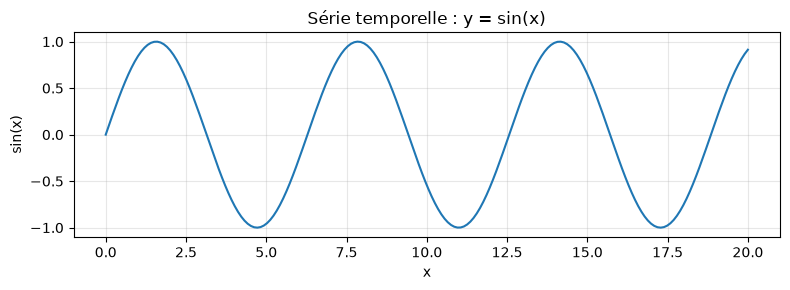

In [2]:
import torch.nn as nn

# Générer 200 valeurs de sin(x) entre 0 et 20
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

# Découper en séquences de 10 valeurs -> prédire la 11ème
longueur_sequence = 10
X = torch.stack([serie[i : i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])

# Format attendu par PyTorch : (batch, longueur, features)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : 150 pour l'entraînement, 40 pour le test
X_train, y_train = X[:150].to(device), y[:150].to(device)
X_test, y_test = X[150:].to(device), y[150:].to(device)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

plt.figure(figsize=(8, 3))
plt.plot(periode, serie)
plt.title("Série temporelle : y = sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### RNN

Epoch  50 | Perte : 0.001277
Epoch 100 | Perte : 0.000504
Epoch 150 | Perte : 0.000223
Epoch 200 | Perte : 0.000103
Epoch 250 | Perte : 0.000049
Epoch 300 | Perte : 0.000025

Erreur test (MSE) : 0.000028


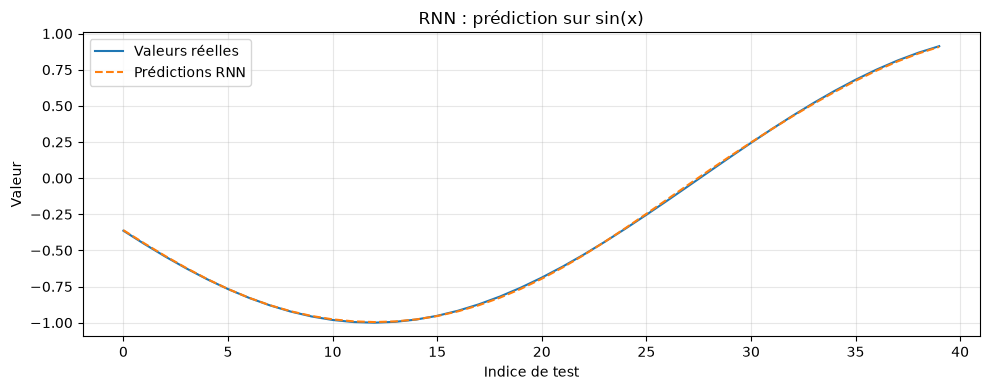

In [3]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.fc = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)
        dernier_etat = etats[:, -1, :]
        return self.fc(dernier_etat)


modele_rnn = SimpleRNN().to(device)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_rnn.parameters(), lr=0.01)

# Entraînement
modele_rnn.train()
for epoch in range(300):
    predictions = modele_rnn(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Perte : {perte.item():.6f}")

# Évaluation sur le test
modele_rnn.eval()
with torch.no_grad():
    pred_rnn = modele_rnn(X_test)
    erreur_test = critere(pred_rnn, y_test)

print(f"\nErreur test (MSE) : {erreur_test.item():.6f}")

plt.figure(figsize=(10, 4))
plt.plot(y_test.cpu().numpy(), label="Valeurs réelles")
plt.plot(pred_rnn.cpu().numpy(), label="Prédictions RNN", linestyle="--")
plt.title("RNN : prédiction sur sin(x)")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### LSTM

Epoch  50 | Perte : 0.002550
Epoch 100 | Perte : 0.000239
Epoch 150 | Perte : 0.000019
Epoch 200 | Perte : 0.000014
Epoch 250 | Perte : 0.000012
Epoch 300 | Perte : 0.000010

Erreur test LSTM (MSE) : 0.000010


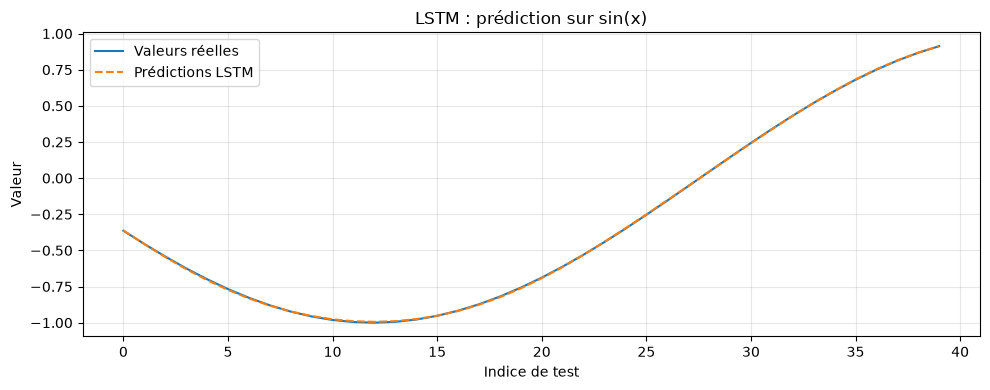

In [4]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, batch_first=True)
        self.fc = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.lstm(x)
        dernier_etat = etats[:, -1, :]
        return self.fc(dernier_etat)


modele_lstm = SimpleLSTM().to(device)
optimiseur_lstm = torch.optim.Adam(modele_lstm.parameters(), lr=0.01)

# Entraînement
modele_lstm.train()
for epoch in range(300):
    predictions = modele_lstm(X_train)
    perte = critere(predictions, y_train)

    optimiseur_lstm.zero_grad()
    perte.backward()
    optimiseur_lstm.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Perte : {perte.item():.6f}")

# Évaluation sur le test
modele_lstm.eval()
with torch.no_grad():
    pred_lstm = modele_lstm(X_test)
    erreur_test = critere(pred_lstm, y_test)

print(f"\nErreur test LSTM (MSE) : {erreur_test.item():.6f}")

plt.figure(figsize=(10, 4))
plt.plot(y_test.cpu().numpy(), label="Valeurs réelles")
plt.plot(pred_lstm.cpu().numpy(), label="Prédictions LSTM", linestyle="--")
plt.title("LSTM : prédiction sur sin(x)")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Transformer

Epoch  50 | Perte : 0.000699
Epoch 100 | Perte : 0.000503
Epoch 150 | Perte : 0.002312
Epoch 200 | Perte : 0.000117
Epoch 250 | Perte : 0.000060
Epoch 300 | Perte : 0.000037

Erreur test Transformer (MSE) : 0.000052


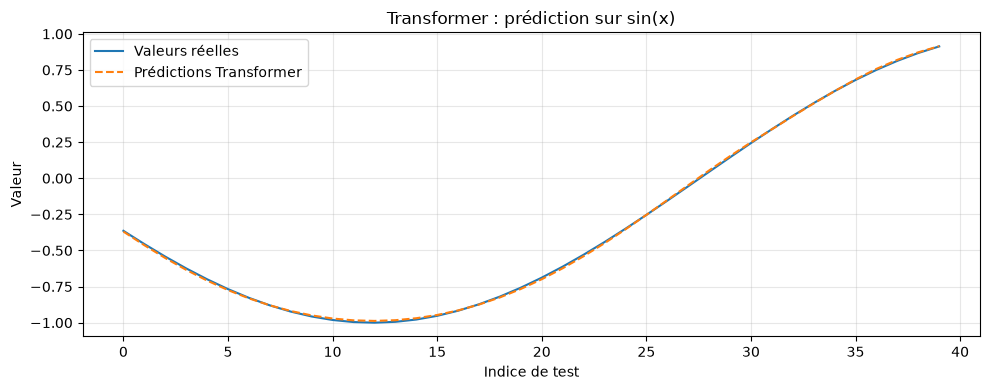

In [5]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()
        d_model = 16
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur_max, d_model)

        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        longueur = x.size(1)
        x = self.projection(x)
        indices = torch.arange(longueur, device=x.device)
        x = x + self.positions(indices).unsqueeze(0)
        representations = self.encodeur(x)
        return self.fc(representations[:, -1, :])


modele_tr = MiniTransformer(longueur_max=longueur_sequence).to(device)
optimiseur_tr = torch.optim.Adam(modele_tr.parameters(), lr=0.01)

# Entraînement
modele_tr.train()
for epoch in range(300):
    predictions = modele_tr(X_train)
    perte = critere(predictions, y_train)

    optimiseur_tr.zero_grad()
    perte.backward()
    optimiseur_tr.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Perte : {perte.item():.6f}")

# Évaluation sur le test
modele_tr.eval()
with torch.no_grad():
    pred_tr = modele_tr(X_test)
    erreur_test = critere(pred_tr, y_test)

print(f"\nErreur test Transformer (MSE) : {erreur_test.item():.6f}")

plt.figure(figsize=(10, 4))
plt.plot(y_test.cpu().numpy(), label="Valeurs réelles")
plt.plot(pred_tr.cpu().numpy(), label="Prédictions Transformer", linestyle="--")
plt.title("Transformer : prédiction sur sin(x)")
plt.xlabel("Indice de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### GPT : génération de texte

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_gpt = "gpt2"
tokenizer_gpt = AutoTokenizer.from_pretrained(nom_gpt)
modele_gpt = AutoModelForCausalLM.from_pretrained(nom_gpt)

tokenizer_gpt.pad_token = tokenizer_gpt.eos_token
modele_gpt.config.pad_token_id = tokenizer_gpt.pad_token_id
modele_gpt.eval()

amorce = "Artificial intelligence can help people"
entrees_gpt = tokenizer_gpt(amorce, return_tensors="pt")

with torch.no_grad():
    sortie_gpt = modele_gpt.generate(
        **entrees_gpt,
        max_new_tokens=40,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer_gpt.pad_token_id,
    )

print("Amorce :", amorce)
print("Texte généré :")
print(tokenizer_gpt.decode(sortie_gpt[0], skip_special_tokens=True))

Amorce : Artificial intelligence can help people
Texte généré :
Artificial intelligence can help people find solutions to a myriad of problems. It could be an option for the public at large.

In the meantime, the question is whether the AI will be able to provide us with a new


W1121 10:04:00.384000 85524 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|##########| 148/148 [00:00<00:00, 6547.24it/s]


### BERT : prédiction d’un mot masqué

In [7]:
from transformers import AutoTokenizer, AutoModelForMaskedLM

nom_bert = "bert-base-multilingual-cased"
tokenizer_bert = AutoTokenizer.from_pretrained(nom_bert)
modele_bert = AutoModelForMaskedLM.from_pretrained(nom_bert)
modele_bert.eval()

phrase_masquee = f"Rabat est la {tokenizer_bert.mask_token} du Maroc."
entrees_bert = tokenizer_bert(phrase_masquee, return_tensors="pt")

pos_masque = (entrees_bert["input_ids"][0] == tokenizer_bert.mask_token_id).nonzero(as_tuple=True)[0].item()

with torch.no_grad():
    logits = modele_bert(**entrees_bert).logits

probas = torch.softmax(logits[0, pos_masque, :], dim=-1)
top_probas, top_indices = torch.topk(probas, k=5)

print("Phrase :", phrase_masquee)
print("\nTop 5 propositions :")
for p_val, idx in zip(top_probas, top_indices):
    mot = tokenizer_bert.decode([idx.item()]).strip()
    print(f"  {p_val.item():6.2%} -> {phrase_masquee.replace(tokenizer_bert.mask_token, mot)}")

Phrase : Rabat est la [MASK] du Maroc.

Top 5 propositions :
  86.07% -> Rabat est la capitale du Maroc.
   5.19% -> Rabat est la ville du Maroc.
   5.03% -> Rabat est la préfecture du Maroc.
   0.85% -> Rabat est la Rabat du Maroc.
   0.58% -> Rabat est la capital du Maroc.


Loading weights: 100%|##########| 202/202 [00:00<00:00, 11985.93it/s]
